# TRM exploratory analysis

TRM is the USD/COP representative market exchange rate, expressed as Colombian pesos per US dollar. The analysis uses consecutive observed values. A non-publication day is not automatically a missing observation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from trm_forecast.data.audit import audit_trm

DATA_PATH = next(path / "data/interim/trm_normalized.csv" for path in [Path.cwd(), *Path.cwd().parents] if (path / "data/interim/trm_normalized.csv").exists())
data = pd.read_csv(DATA_PATH)
report = audit_trm(data)
data.info()
display(data.head())
display(pd.DataFrame([{"shape": data.shape, "earliest": report.earliest_date, "latest": report.latest_date, "valid_observations": report.observation_count}]))

<class 'pandas.DataFrame'>
RangeIndex: 4456 entries, 0 to 4455
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          4456 non-null   str    
 1   trm           4456 non-null   float64
 2   source        4456 non-null   str    
 3   retrieved_at  4456 non-null   str    
dtypes: float64(1), str(3)
memory usage: 139.4 KB


,date,trm,source,retrieved_at
0,2008-01-03,2012.82,Datos Abiertos Colombia: ceyp-9c7c,2026-10-20 02:00:56.369189
1,2008-01-04,2013.27,Datos Abiertos Colombia: ceyp-9c7c,2026-10-20 02:00:56.369189
2,2008-01-05,2013.98,Datos Abiertos Colombia: ceyp-9c7c,2026-10-20 02:00:56.369189
3,2008-01-09,2000.91,Datos Abiertos Colombia: ceyp-9c7c,2026-10-20 02:00:56.369189
4,2008-01-10,2004.70,Datos Abiertos Colombia: ceyp-9c7c,2026-10-20 02:00:56.369189


,shape,earliest,latest,valid_observations
0,"(4456, 4)",2008-01-03,2026-10-20,4456


In [2]:
analysis = data.copy()
analysis["date"] = pd.to_datetime(analysis["date"], errors="coerce")
analysis["trm"] = pd.to_numeric(analysis["trm"], errors="coerce")
analysis = analysis.dropna(subset=["date", "trm"]).sort_values("date").copy()
analysis["daily_change_cop"] = analysis["trm"].diff()
analysis["log_return"] = np.log(analysis["trm"]).diff()
analysis["pct_change"] = analysis["trm"].pct_change() * 100

display(analysis["trm"].describe().to_frame("TRM (COP per USD)"))
display(analysis[["date", "trm", "daily_change_cop", "pct_change", "log_return"]])

,TRM (COP per USD)
count,4456.000000
mean,2948.523820
std,912.685451
min,1652.410000
25%,1936.555000
50%,2973.670000
75%,3776.092500
max,5061.210000


,date,trm,daily_change_cop,pct_change,log_return
0,2008-01-03,2012.82,NaN,NaN,NaN
1,2008-01-04,2013.27,0.45,0.022357,0.000224
2,2008-01-05,2013.98,0.71,0.035266,0.000353
3,2008-01-09,2000.91,-13.07,-0.648964,-0.006511
4,2008-01-10,2004.70,3.79,0.189414,0.001892
...,...,...,...,...,...
4451,2026-10-14,3181.74,-12.70,-0.397566,-0.003984
4452,2026-10-15,3197.65,15.91,0.500041,0.004988
4453,2026-10-16,3170.46,-27.19,-0.850312,-0.008539
4454,2026-10-17,3174.67,4.21,0.132788,0.001327


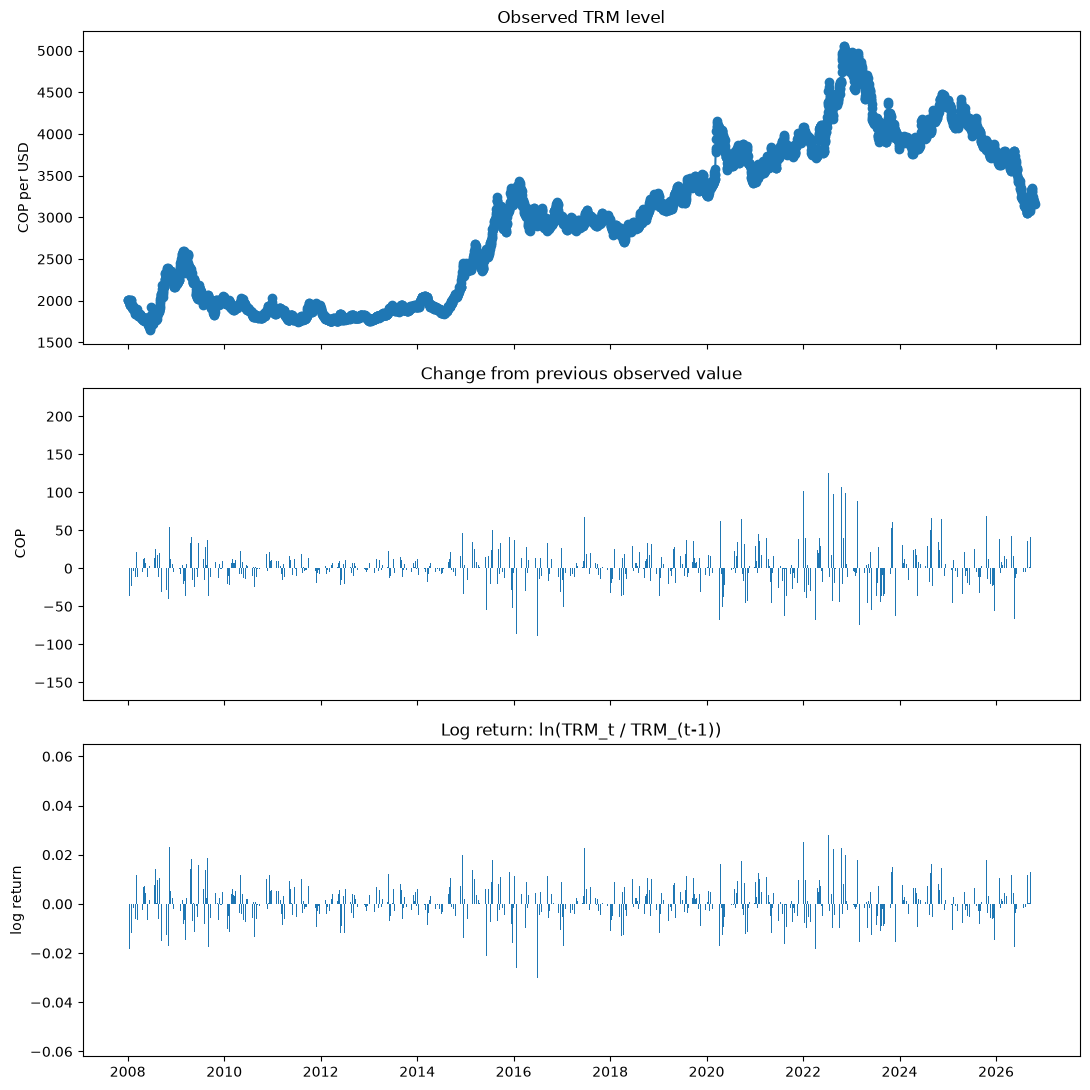

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
axes[0].plot(analysis["date"], analysis["trm"], marker="o")
axes[0].set_ylabel("COP per USD")
axes[0].set_title("Observed TRM level")
axes[1].bar(analysis["date"], analysis["daily_change_cop"], width=0.8)
axes[1].set_ylabel("COP")
axes[1].set_title("Change from previous observed value")
axes[2].bar(analysis["date"], analysis["log_return"], width=0.8)
axes[2].set_ylabel("log return")
axes[2].set_title("Log return: ln(TRM_t / TRM_(t-1))")
fig.tight_layout()

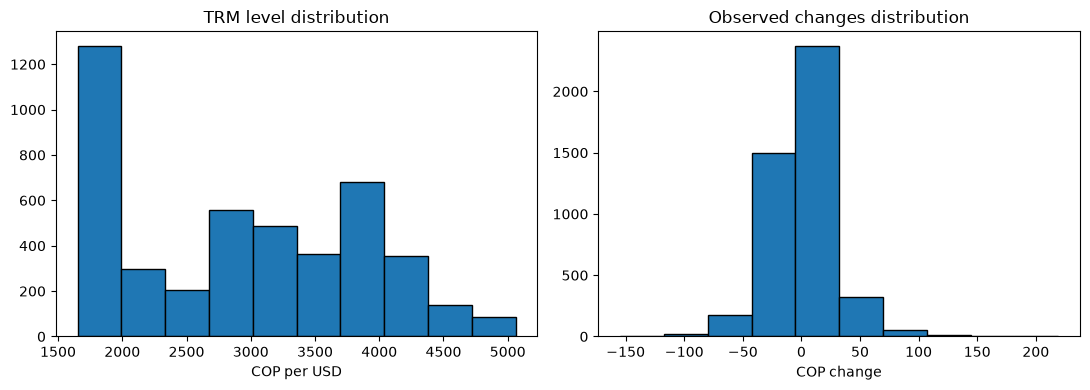

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(analysis["trm"], bins=min(10, max(1, len(analysis))), edgecolor="black")
axes[0].set_xlabel("COP per USD")
axes[0].set_title("TRM level distribution")
axes[1].hist(analysis["daily_change_cop"].dropna(), bins=min(10, max(1, len(analysis)-1)), edgecolor="black")
axes[1].set_xlabel("COP change")
axes[1].set_title("Observed changes distribution")
fig.tight_layout()

In [5]:
changes = analysis.dropna(subset=["daily_change_cop"]).copy()
if len(changes) >= 3:
    threshold = changes["daily_change_cop"].abs().quantile(0.95)
    unusual = changes[changes["daily_change_cop"].abs() >= threshold]
else:
    threshold = np.nan
    unusual = changes.iloc[0:0]
display(unusual[["date", "trm", "daily_change_cop", "pct_change"]])
print("These are screening candidates for source/context review, not automatic errors.")

,date,trm,daily_change_cop,pct_change
117,2008-06-28,1923.02,90.21,4.921950
119,2008-07-03,1818.60,-96.84,-5.055757
120,2008-07-04,1748.43,-70.17,-3.858463
172,2008-09-20,2067.45,-119.56,-5.466825
175,2008-09-25,2147.41,69.82,3.360625
...,...,...,...,...
4402,2026-07-31,3132.42,-73.76,-2.300557
4404,2026-08-04,3230.44,86.30,2.744789
4421,2026-08-29,3202.79,58.51,1.860839
4439,2026-09-25,3329.61,65.22,1.997923


These are screening candidates for source/context review, not automatic errors.


In [6]:
audit_table = pd.DataFrame([{key: value for key, value in report.to_dict().items() if not isinstance(value, (tuple, list))}]).T.rename(columns={0: "value"})
display(audit_table)
display(pd.DataFrame(report.candidate_missing_periods))

,value
input_rows,4456
observation_count,4456
earliest_date,2008-01-03
latest_date,2026-10-20
unique_date_count,4456
duplicated_date_count,0
rows_in_duplicated_dates,0
missing_date_count,0
invalid_date_count,0
missing_value_count,0


,start,end,calendar_days,business_days_monday_friday
0,2008-01-05,2008-01-09,4,2
1,2008-01-12,2008-01-15,3,1
2,2008-01-19,2008-01-23,4,2
3,2008-01-26,2008-01-29,3,1
4,2008-02-02,2008-02-05,3,1
...,...,...,...,...
1054,2026-09-19,2026-09-22,3,1
1055,2026-09-26,2026-09-29,3,1
1056,2026-10-03,2026-10-06,3,1
1057,2026-10-10,2026-10-14,4,2


## Interpretation and limitations

The level is a price in COP per USD; changes and returns measure movement between consecutive published observations and therefore answer different questions. Visual fit to historical levels is not enough for forecasting: errors, stability across origins, forecast horizons, and leakage-aware evaluation matter. A historical pattern does not establish persistence over the next 1–10 business days.

This file is only five observations long, so distributional and unusually-large-change results are descriptive and not statistically stable. The local file has not been independently checked against the live source in this notebook; any suspicious discontinuity requires source and institutional-calendar review.